In [ ]:
# function to make tables for each figure

In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display, HTML
from html import escape

RESULTS_DIR = Path(
    "/Users/..."
)

# Format numbers consistently, using a true minus sign.
def format_number(value, decimals=3):
    if pd.isna(value):
        return "—"

    value = float(value)

    # Prevent displaying negative zero after rounding.
    if round(value, decimals) == 0:
        value = 0.0

    return f"{value:.{decimals}f}".replace("-", "−")


def format_p(value):
    if pd.isna(value):
        return "—"

    value = float(value)

    if not 0 <= value <= 1:
        raise ValueError(f"Invalid p value: {value}")

    if value < 0.001:
        return "< .001"

    return f"{value:.3f}".removeprefix("0")


def show_ame_table(csv_path, title):
    # Reload raw results to avoid altered plotting dataframes.
    raw = pd.read_csv(csv_path)

    required = [
        "Predictor", "AME", "SE",
        "CI_low", "CI_high", "p_value",
    ]

    missing = set(required) - set(raw.columns)
    if missing:
        raise ValueError(f"Missing columns in {csv_path}: {sorted(missing)}")

    predictor_labels = {
        "Z1": "Other-viewer synchrony (OVS)",
        "Z2": "Individual-to-group synchrony (IGS)",
        "mean_correct_YN_LOO":
            "Other participants’ mean YN accuracy",
        "mean_correct_2AFC_LOO":
            "Other participants’ mean 2AFC accuracy",
        "mean_correct_YN_LOO_signal_present":
            "Other participants’ mean YN accuracy (signal present)",
        "mean_correct_YN_LOO_signal_absent":
            "Other participants’ mean YN accuracy (signal absent)",
    }

    # Place synchrony predictors first, followed by covariates.
    raw["_order"] = raw["Predictor"].map({"Z1": 0, "Z2": 1}).fillna(2)
    raw = raw.sort_values("_order", kind="stable")

    # Convert AME, SE, and CI together to percentage points.
    scaled = raw[["AME", "SE", "CI_low", "CI_high"]].apply(
        pd.to_numeric, errors="raise"
    ) * 100

    table = pd.DataFrame({
        "Predictor": raw["Predictor"].map(predictor_labels).fillna(
            raw["Predictor"]
        ),
        "AME": scaled["AME"].map(format_number),
        "SE": scaled["SE"].map(format_number),
        "95% CI": [
            f"[{format_number(low)}, {format_number(high)}]"
            for low, high in zip(scaled["CI_low"], scaled["CI_high"])
        ],
        "p": raw["p_value"].map(format_p),
    }).reset_index(drop=True)

    header = (
        "<tr>"
        "<th>Predictor</th>"
        "<th>AME</th>"
        "<th><i>SE</i></th>"
        "<th>95% CI</th>"
        "<th><i>p</i></th>"
        "</tr>"
    )

    rows = "".join(
        "<tr>"
        + "".join(f"<td>{escape(str(value))}</td>" for value in row)
        + "</tr>"
        for row in table.itertuples(index=False, name=None)
    )

    note = (
    "AME = average marginal effect; CI = confidence interval; "
    "SE = standard error; OVS = other-viewer synchrony; "
    "IGS = individual-to-group synchrony. "
    "AMEs, SEs, and confidence limits are expressed in percentage "
    "points per one-unit increase in the corresponding model predictor. "
    "OVS and IGS refer to the decomposed synchrony predictors "
    "described in the main text. Other participants’ mean accuracy "
    "is a leave-one-out measure."
)

    display(HTML(f"""
    <style>
        .ame-results {{
            font-family: Arial, Helvetica, sans-serif;
            color: #111;
            max-width: 1000px;
            margin: 16px 0 28px;
        }}
        .ame-results h4 {{
            font-size: 15px;
            margin: 0 0 10px;
        }}
        .ame-results table {{
            width: 100%;
            border-collapse: collapse;
            border-top: 1.5px solid #111;
            border-bottom: 1.5px solid #111;
            font-size: 13px;
        }}
        .ame-results th,
        .ame-results td {{
            padding: 9px 12px;
            border: none;
            text-align: right;
            background: white;
            font-variant-numeric: tabular-nums;
        }}
        .ame-results thead {{
            border-bottom: 1px solid #111;
        }}
        .ame-results th {{
            font-weight: normal;
            white-space: nowrap;
        }}
        .ame-results th:first-child,
        .ame-results td:first-child {{
            text-align: left;
            width: 48%;
        }}
        .ame-results td:not(:first-child) {{
            white-space: nowrap;
        }}
        .ame-results p {{
            font-size: 12px;
            line-height: 1.5;
            margin-top: 9px;
        }}
    </style>

    <div class="ame-results">
        <h4>{escape(title)}</h4>
        <table>
            <thead>{header}</thead>
            <tbody>{rows}</tbody>
        </table>
        <p><i>Note.</i> {escape(note)}</p>
    </div>
    """))

    return table

In [ ]:
#FIGURE 3

In [ ]:
#first we need to load the data and run GLMM
import pandas as pd

df = pd.read_csv(
    "/Users/.../all_movies_merged_sync_behav_with_group_LOO_behavioural_accuracy_30_subjects_final.csv"
)


In [ ]:
%load_ext rpy2.ipython


In [ ]:
%%R -i df
library(lme4)
library(marginaleffects)


# (Recompute Z1/Z2 if needed; safe to keep)
df$pilot_z <- as.numeric(scale(df$pilot_mean))
df$group_z <- as.numeric(scale(df$group_mean))
df$Z1 <- (df$pilot_z + df$group_z) / 2
df$Z2 <- (df$pilot_z - df$group_z) / 2

glmm_decomp_yn <- glmer(
  correct_response_occlusion ~
    Z1 +
    Z2 +
    mean_correct_YN_LOO +
    (1 | participant_id),
  data = df,
  family = binomial(link = "logit"),
  control = glmerControl(optimizer = "bobyqa")
)

ame_yn <- avg_slopes(glmm_decomp_yn, variables = c("Z1","Z2","mean_correct_YN_LOO"), type = "response")
ame_yn_df <- as.data.frame(ame_yn)

ame_yn_out <- data.frame(
  Predictor = ame_yn_df$term,
  AME       = ame_yn_df$estimate,
  CI_low    = ame_yn_df$conf.low,
  CI_high   = ame_yn_df$conf.high,
  SE        = ame_yn_df$std.error,
  p_value   = ame_yn_df$p.value
)


label_map <- c(
  Z1 = "(individual sync + group sync)/2",
  Z2 = "(individual sync - group sync)/2",
  mean_correct_YN_LOO = "mean_correct_YN_LOO"
)
ame_yn_out$label <- unname(label_map[ame_yn_out$Predictor])

OUT_PATH <- "/Users/.../YN_decomposition_AME_30_subjects.csv"
write.csv(ame_yn_out, OUT_PATH, row.names = FALSE)

ame_yn_out


In [ ]:
#the same but for 2AFC task

In [ ]:
%%R -i df
library(lme4)
library(marginaleffects)

# ----------------------------
# Create decomposition predictors
# ----------------------------
df$pilot_z <- as.numeric(scale(df$pilot_mean))
df$group_z <- as.numeric(scale(df$group_mean))

df$Z1 <- (df$pilot_z + df$group_z) / 2   # shared synchrony
df$Z2 <- (df$pilot_z - df$group_z) / 2   # individual deviation from group

# ----------------------------
# Fit GLMM (2AFC)
# ----------------------------
glmm_decomp_2afc <- glmer(
  accuracy ~
    Z1 +
    Z2 +
    mean_correct_2AFC_LOO +
    (1 | participant_id),
  data = df,
  family = binomial(link = "logit"),
  control = glmerControl(optimizer = "bobyqa")
)

summary(glmm_decomp_2afc)

# ----------------------------
# Average Marginal Effects (probability scale)
# ----------------------------
# type="response" => effects in ΔP (change in predicted probability)
ame_2afc <- avg_slopes(
  glmm_decomp_2afc,
  variables = c("Z1", "Z2", "mean_correct_2AFC_LOO"),
  type = "response"
)

ame_2afc


In [ ]:
%%R
ame_2afc_df <- as.data.frame(ame_2afc)


# Keep only what you need for plotting
ame_2afc_out <- data.frame(
  Predictor = ame_2afc_df$term,
  AME       = ame_2afc_df$estimate,
  CI_low    = ame_2afc_df$conf.low,
  CI_high   = ame_2afc_df$conf.high,
  SE        = ame_2afc_df$std.error,
  p_value   = ame_2afc_df$p.value
)

# Add the same labels you used before
label_map <- c(
  Z1 = "(individual sync + group sync)/2",
  Z2 = "(individual sync - group sync)/2",
mean_correct_2AFC_LOO = "mean_correct_2AFC_LOO"
)
ame_2afc_out$label <- unname(label_map[ame_2afc_out$Predictor])

OUT_PATH <- "/Users/.../ame_2afc_marginal_effects_decomposition.csv"
write.csv(ame_2afc_out, OUT_PATH, row.names = FALSE)

ame_2afc_out


In [ ]:
#visualising the GLMM results for the YN task and 2AFC task

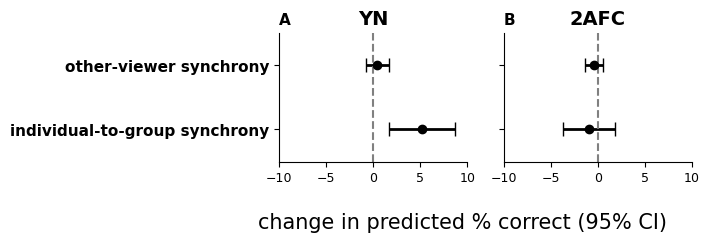

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter


# -------------------------------------------------
# Paths
# -------------------------------------------------
yn_path   = "/Users/.../YN_decomposition_AME_30_subjects.csv"
afc_path  = "/Users/.../2AFC_decomposition_AME_30_subjects.csv"

df_yn   = pd.read_csv(yn_path)
df_2afc = pd.read_csv(afc_path)

df_yn = df_yn[df_yn["Predictor"].isin(["Z1", "Z2"])].copy()
df_2afc = df_2afc[df_2afc["Predictor"].isin(["Z1", "Z2"])].copy()



# -------------------------------------------------
# Label harmonization
# -------------------------------------------------
label_map = {
    "Z1": "other-viewer synchrony",
    "Z2": "individual-to-group synchrony"
}

if "Predictor" in df_yn.columns:
    df_yn["label_plot"] = df_yn["Predictor"].map(label_map).fillna(df_yn.get("label", df_yn["Predictor"]))
else:
    df_yn["label_plot"] = df_yn["label"]

if "Predictor" in df_2afc.columns:
    df_2afc["label_plot"] = df_2afc["Predictor"].map(label_map).fillna(df_2afc.get("label", df_2afc["Predictor"]))
else:
    df_2afc["label_plot"] = df_2afc["label"]

order = ["other-viewer synchrony", "individual-to-group synchrony"]

df_yn["label_plot"]   = pd.Categorical(df_yn["label_plot"], categories=order, ordered=True)
df_2afc["label_plot"] = pd.Categorical(df_2afc["label_plot"], categories=order, ordered=True)

df_yn   = df_yn.sort_values("label_plot").reset_index(drop=True)
df_2afc = df_2afc.sort_values("label_plot").reset_index(drop=True)

# -------------------------------------------------
# Plot
# -------------------------------------------------
fig, (ax_yn, ax_2afc) = plt.subplots(1, 2, figsize=(7.2, 2.4), sharey=True)

y_pos = np.arange(len(df_yn))

# Convert to percentage points
for df in (df_yn, df_2afc):
    df["AME_pp"] = df["AME"] *100
    df["CI_low_pp"] = df["CI_low"] *100
    df["CI_high_pp"] = df["CI_high"] *100

# ---- YN ----
ax_yn.errorbar(
    df_yn["AME_pp"],
    y_pos,
    xerr=[df_yn["AME_pp"] - df_yn["CI_low_pp"],
          df_yn["CI_high_pp"] - df_yn["AME_pp"]],
    fmt="o",
    color="black",
    ecolor="black",
    elinewidth=2,
    capsize=5,
    markersize=6
)
ax_yn.axvline(0, linestyle="--", color="gray", linewidth=1.5)
ax_yn.set_title("YN", fontsize=14, weight="bold")


# ---- 2AFC ----

ax_2afc.errorbar(
    df_2afc["AME_pp"],
    y_pos,
    xerr=[df_2afc["AME_pp"] - df_2afc["CI_low_pp"],
          df_2afc["CI_high_pp"] - df_2afc["AME_pp"]],
    fmt="o",
    color="black",
    ecolor="black",
    elinewidth=2,
    capsize=5,
    markersize=6
)
ax_2afc.axvline(0, linestyle="--", color="gray", linewidth=1.5)
ax_2afc.set_title("2AFC", fontsize=14, weight="bold")


# ---- Shared Y axis labels ----
ax_yn.set_yticks(y_pos)
ax_yn.set_yticklabels(df_yn["label_plot"].astype(str).values, fontsize=11, fontweight="bold")
ax_yn.invert_yaxis()

# ---- Symmetric x-limits around zero ----
all_vals = np.concatenate([
    df_yn["CI_low_pp"].values, df_yn["CI_high_pp"].values,
    df_2afc["CI_low_pp"].values, df_2afc["CI_high_pp"].values
])

m = np.max(np.abs(all_vals)) * 1.15
for ax in (ax_yn, ax_2afc):
    ax.set_xticks(np.arange(-10, 11, 5))

# ---- Format x-axis as percentages ----
# AME values are probabilities, so 0.05 will display as 5%
for ax in (ax_yn, ax_2afc):
    
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", labelsize=9)

ax_yn.set_ylim(len(y_pos) - 0.5, -0.5)

#set x axis from -5 to 10
ax_yn.set_xlim(-10, 10)
ax_2afc.set_xlim(-10, 10)

# title for x-axis

fig.supxlabel("change in predicted % correct (95% CI)", fontsize=15, x = 0.65)
# Bold panel labels: A = YN; B = 2AFC
ax_yn.set_title("A", loc="left", fontsize=11, fontweight="bold")
ax_2afc.set_title("B", loc="left", fontsize=11, fontweight="bold")

plt.tight_layout()

out_path = "/Users/.../YN_2AFC_AME_forestplot.png"
plt.savefig(out_path, dpi=1200, bbox_inches="tight")

plt.show()



In [10]:
# FIGURE 3 — Formatted results tables

fig3_yn_table = show_ame_table(
    RESULTS_DIR / "YN_decomposition_AME_30_subjects.csv",
    "Figure 3 — YN Task",
)

fig3_2afc_table = show_ame_table(
    RESULTS_DIR / "2AFC_decomposition_AME_30_subjects.csv",
    "Figure 3 — 2AFC Task",
)

Predictor,AME,SE,95% CI,p
Other-viewer synchrony (OVS),0.428,0.628,"[−0.804, 1.660]",.496
Individual-to-group synchrony (IGS),5.165,1.795,"[1.646, 8.685]",.004
Other participants’ mean YN accuracy,0.694,0.036,"[0.623, 0.764]",< .001


Predictor,AME,SE,95% CI,p
Other-viewer synchrony (OVS),−0.408,0.479,"[−1.348, 0.532]",.395
Individual-to-group synchrony (IGS),−0.957,1.409,"[−3.719, 1.805]",.497
Other participants’ mean 2AFC accuracy,0.654,0.028,"[0.600, 0.709]",< .001


In [ ]:
#FIGURE 4
# first, fitting the GLMM model for signal absent

In [ ]:
%%R
library(lme4)
library(marginaleffects)

# -------------------------------------------------
# Load full dataset
# -------------------------------------------------
df <- read.csv("/Users/.../all_movies_merged_sync_behav_with_signal_absent_LOO_30_subjects.csv")

# Ensure factor
df$participant_id <- as.factor(df$participant_id)

# -------------------------------------------------
# z-score and decompose 
# -------------------------------------------------
df$pilot_z <- as.numeric(scale(df$pilot_mean))
df$group_z <- as.numeric(scale(df$group_mean))

df$Z1 <- (df$pilot_z + df$group_z) / 2   # shared synchrony
df$Z2 <- (df$pilot_z - df$group_z) / 2   # individual-specific synchrony

# -------------------------------------------------
# Keep ONLY signal-absent trials (CR + FA)
# -------------------------------------------------
df_signal_absent <- droplevels(subset(df, !is.na(signal_absent)))

# -------------------------------------------------
# Sanity checks
# -------------------------------------------------
cat("===== Sanity checks: signal-absent subset =====\n")
cat("Rows used:", nrow(df_signal_absent), "\n")
cat("Unique participants:", length(unique(df_signal_absent$participant_id)), "\n\n")

cat("Distribution of signal_absent (should be 0/1 only):\n")
print(table(df_signal_absent$signal_absent, useNA = "ifany"))
cat("\n")

cat("Response x Correctness (should reflect CR/FA coding):\n")
print(table(df_signal_absent$response_occlusion,
            df_signal_absent$correct_response_occlusion,
            useNA = "ifany"))
cat("\n")

# -------------------------------------------------
# GLMM using decomposed predictors
# -------------------------------------------------
glmm_signal_absent <- glmer(
  correct_response_occlusion ~
    Z1 +
    Z2 +
    mean_correct_YN_LOO_signal_absent +
    (1 | participant_id),
  data = df_signal_absent,
  family = binomial(link = "logit"),
  control = glmerControl(optimizer = "bobyqa")
)

summary(glmm_signal_absent)

# -------------------------------------------------
# Average Marginal Effects
# -------------------------------------------------
ame_abs <- avg_slopes(
  glmm_signal_absent,
  variables = c("Z1", "Z2", "mean_correct_YN_LOO_signal_absent"),
  type = "response"
)

ame_df <- as.data.frame(ame_abs)

out <- data.frame(
  Predictor = ame_df$term,
  AME       = ame_df$estimate,
  CI_low    = ame_df$conf.low,
  CI_high   = ame_df$conf.high,
  SE        = ame_df$std.error,
  p_value   = ame_df$p.value
)

# -------------------------------------------------
# Labels
# -------------------------------------------------
label_map <- c(
  Z1 = "Group synchrony (decomposed)",
  Z2 = "Individual-to-group synchrony (decomposed)",
  mean_correct_YN_LOO_signal_absent = "Mean correct (YN, signal-absent)"
)

out$label_plot <- unname(label_map[out$Predictor])

# -------------------------------------------------
# Save
# -------------------------------------------------
out_path <- "/Users/.../YN_AME_signal_absent_decomposed.csv"
write.csv(out, out_path, row.names = FALSE)

cat("\nSaved AME table to:\n", out_path, "\n\n")
out

In [ ]:
#FIGURE 4
#fitting GLMM on signal-present trials  

In [ ]:
%%R
library(lme4)
library(marginaleffects)

# -------------------------------------------------
# Load full dataset (signal-present version)
# -------------------------------------------------
df <- read.csv("/.../all_movies_merged_sync_behav_with_signal_present_LOO_30_subjects.csv")

# Ensure factor
df$participant_id <- as.factor(df$participant_id)

# -------------------------------------------------
# Decompose synchrony on FULL dataset
# -------------------------------------------------
df$pilot_z <- as.numeric(scale(df$pilot_mean))
df$group_z <- as.numeric(scale(df$group_mean))

df$Z1 <- (df$pilot_z + df$group_z) / 2
df$Z2 <- (df$pilot_z - df$group_z) / 2

# -------------------------------------------------
# Keep ONLY signal-present trials (hits + misses)
# -------------------------------------------------
df_signal_present <- droplevels(subset(df, !is.na(signal_present)))

# -------------------------------------------------
# Sanity checks
# -------------------------------------------------
cat("===== Sanity checks: signal-present subset =====\n")
cat("Rows used:", nrow(df_signal_present), "\n")
cat("Unique participants:", length(unique(df_signal_present$participant_id)), "\n\n")

cat("Distribution of signal_present (should be 0/1 only):\n")
print(table(df_signal_present$signal_present, useNA = "ifany"))
cat("\n")

cat("Response x Correctness (should reflect hit/miss coding):\n")
print(table(df_signal_present$response_occlusion,
            df_signal_present$correct_response_occlusion,
            useNA = "ifany"))
cat("\n")

# -------------------------------------------------
# GLMM using decomposed predictors
# -------------------------------------------------
glmm_signal_present <- glmer(
  correct_response_occlusion ~
    Z1 +
    Z2 +
    mean_correct_YN_LOO_signal_present +
    (1 | participant_id),
  data = df_signal_present,
  family = binomial(link = "logit"),
  control = glmerControl(optimizer = "bobyqa")
)

summary(glmm_signal_present)

# -------------------------------------------------
# Average Marginal Effects
# -------------------------------------------------
ame_abs <- avg_slopes(
  glmm_signal_present,
  variables = c("Z1", "Z2", "mean_correct_YN_LOO_signal_present"),
  type = "response"
)

ame_df <- as.data.frame(ame_abs)

out <- data.frame(
  Predictor = ame_df$term,
  AME       = ame_df$estimate,
  CI_low    = ame_df$conf.low,
  CI_high   = ame_df$conf.high,
  SE        = ame_df$std.error,
  p_value   = ame_df$p.value
)

# -------------------------------------------------
# Labels
# -------------------------------------------------
label_map <- c(
  Z1 = "Group synchrony (decomposed)",
  Z2 = "Individual-to-group synchrony (decomposed)",
  mean_correct_YN_LOO_signal_present = "Mean correct (YN, signal-present)"
)

out$label_plot <- unname(label_map[out$Predictor])

# -------------------------------------------------
# Save
# -------------------------------------------------
out_path <- "/Users/olgagulka/Desktop/IBS/eye_tracking/scripts_sync_analysis/GLMM_results_plotting/YN_AME_signal_present_decomposed.csv"
write.csv(out, out_path, row.names = FALSE)

cat("\nSaved AME table to:\n", out_path, "\n\n")
out

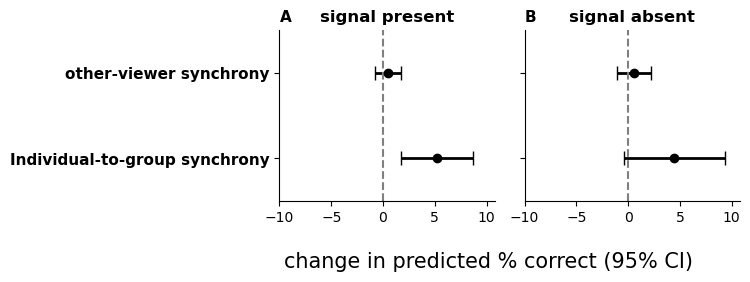

Saved: /Users/olgagulka/Desktop/IBS/eye_tracking/scripts_sync_analysis/GLMM_results_plotting/YN_present_absent_AME_forestplot_decomposed.png


In [ ]:
## FIGURE 4
# plotting signal present and absent marginal effect GLMM results on all trials for IGS and OVS (values are already after removing multicollinearity)

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------
# Paths: decomposed AME results
# -------------------------------------------------
present_path = "/Users/.../YN_AME_signal_present_decomposed.csv"
absent_path  = "/Users/.../YN_AME_signal_absent_decomposed.csv"

# -------------------------------------------------
# Load
# -------------------------------------------------
df_p = pd.read_csv(present_path)
df_a = pd.read_csv(absent_path)

# -------------------------------------------------
# Keep only decomposed synchrony predictors
# -------------------------------------------------
df_p = df_p[df_p["Predictor"].isin(["Z1", "Z2"])].copy()
df_a = df_a[df_a["Predictor"].isin(["Z1", "Z2"])].copy()


# -------------------------------------------------
# labels/order
# -------------------------------------------------
label_map = {
    "Z1": "other-viewer synchrony",
    "Z2": "Individual-to-group synchrony"
}

df_p["label_plot"] = df_p["Predictor"].map(label_map)
df_a["label_plot"] = df_a["Predictor"].map(label_map)

order = ["other-viewer synchrony", "Individual-to-group synchrony"]

df_p["label_plot"] = pd.Categorical(df_p["label_plot"], categories=order, ordered=True)
df_a["label_plot"] = pd.Categorical(df_a["label_plot"], categories=order, ordered=True)

df_p = df_p.sort_values("label_plot").reset_index(drop=True)
df_a = df_a.sort_values("label_plot").reset_index(drop=True)

# -------------------------------------------------
# Convert AME + CI to percentage points
# -------------------------------------------------
for df in (df_p, df_a):
    df["AME_pp"] = df["AME"] * 100
    df["CI_low_pp"] = df["CI_low"] * 100
    df["CI_high_pp"] = df["CI_high"] * 100

# -------------------------------------------------
# Plot
# -------------------------------------------------
y_pos = np.arange(len(df_p))
fig, (ax_p, ax_a) = plt.subplots(1, 2, figsize=(7.6, 2.8), sharey=True)

# ---- signal present ----
ax_p.errorbar(
    df_p["AME_pp"],
    y_pos,
    xerr=[
        df_p["AME_pp"] - df_p["CI_low_pp"],
        df_p["CI_high_pp"] - df_p["AME_pp"]
    ],
    fmt="o",
    color="black",
    ecolor="black",
    elinewidth=2,
    capsize=5,
    markersize=6
)
ax_p.axvline(0, linestyle="--", color="gray", linewidth=1.5)
ax_p.set_title("signal present", fontsize=12, weight="bold")


# ---- signal absent ----
ax_a.errorbar(
    df_a["AME_pp"],
    y_pos,
    xerr=[
        df_a["AME_pp"] - df_a["CI_low_pp"],
        df_a["CI_high_pp"] - df_a["AME_pp"]
    ],
    fmt="o",
    color="black",
    ecolor="black",
    elinewidth=2,
    capsize=5,
    markersize=6
)
ax_a.axvline(0, linestyle="--", color="gray", linewidth=1.5)
ax_a.set_title("signal absent", fontsize=12, weight="bold")


# -------------------------------------------------
# -------------------------------------------------
ax_p.set_yticks(y_pos)
ax_p.set_yticklabels(df_p["label_plot"].astype(str).values, fontsize=11, fontweight="bold")
ax_p.invert_yaxis()

# -------------------------------------------------
# Symmetric x-limits across both panels
# -------------------------------------------------
all_vals = np.concatenate([
    df_p["CI_low_pp"].values, df_p["CI_high_pp"].values,
    df_a["CI_low_pp"].values, df_a["CI_high_pp"].values
])

m = np.max(np.abs(all_vals)) * 1.15
ax_p.set_xlim(-10, m)
ax_a.set_xlim(-10, m)


# -------------------------------------------------
# Clean appearance
# -------------------------------------------------
for ax in (ax_p, ax_a):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", labelsize=10)


ax_p.set_ylim(len(y_pos) - 0.5, -0.5)



# title for x-axis

fig.supxlabel("change in predicted % correct (95% CI)", fontsize=15, x = 0.65)
# Bold panel labels: A = YN; B = 2AFC
ax_p.set_title("A", loc="left", fontsize=11, fontweight="bold")
ax_a.set_title("B", loc="left", fontsize=11, fontweight="bold")


plt.tight_layout()

# -------------------------------------------------
# Save
# -------------------------------------------------
out_path = "/Users/.../YN_present_absent_AME_forestplot.png"
plt.savefig(out_path, dpi=400, bbox_inches="tight")
plt.show()




In [11]:
# FIGURE 4 — Formatted results tables

fig4_present_table = show_ame_table(
    RESULTS_DIR / "YN_AME_signal_present_decomposed.csv",
    "Figure 4 — YN Task: Signal Present",
)

fig4_absent_table = show_ame_table(
    RESULTS_DIR / "YN_AME_signal_absent_decomposed.csv",
    "Figure 4 — YN Task: Signal Absent",
)

Predictor,AME,SE,95% CI,p
Other-viewer synchrony (OVS),0.482,0.623,"[−0.739, 1.703]",.439
Individual-to-group synchrony (IGS),5.204,1.783,"[1.709, 8.700]",.004
Other participants’ mean YN accuracy (signal present),0.334,0.055,"[0.226, 0.441]",< .001


Predictor,AME,SE,95% CI,p
Other-viewer synchrony (OVS),0.585,0.826,"[−1.034, 2.203]",.479
Individual-to-group synchrony (IGS),4.473,2.509,"[−0.445, 9.391]",.075
Other participants’ mean YN accuracy (signal absent),0.761,0.017,"[0.727, 0.795]",< .001


In [ ]:
#FIGURE 5

In [ ]:
%%R
ame_2afc_df <- as.data.frame(ame_2afc)


# Keep only what you need for plotting
ame_2afc_out <- data.frame(
  Predictor = ame_2afc_df$term,
  AME       = ame_2afc_df$estimate,
  CI_low    = ame_2afc_df$conf.low,
  CI_high   = ame_2afc_df$conf.high,
  SE        = ame_2afc_df$std.error,
  p_value   = ame_2afc_df$p.value
)

# Add the same labels you used before
label_map <- c(
  Z1 = "(individual sync + group sync)/2",
  Z2 = "(individual sync - group sync)/2",
mean_correct_2AFC_LOO = "mean_correct_2AFC_LOO"
)
ame_2afc_out$label <- unname(label_map[ame_2afc_out$Predictor])

OUT_PATH <- "/Users/.../ame_2afc_marginal_effects_decomposition.csv"
write.csv(ame_2afc_out, OUT_PATH, row.names = FALSE)

ame_2afc_out


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------
# Paths
# -------------------------------------------------

afc_path  = "/Users/.../ame_2afc_marginal_effects_decomposition.csv"


df_2afc = pd.read_csv(afc_path)
df_2afc = df_2afc.dropna(
    subset=["Predictor", "AME", "CI_low", "CI_high"]
).reset_index(drop=True)

# Keep only the two synchrony predictors
df_2afc = df_2afc[
    df_2afc["Predictor"].isin(["Z1", "Z2"])
].copy()

columns_to_percent = ["AME", "CI_low", "CI_high"]
df_2afc[columns_to_percent] *= 100
# -------------------------------------------------
# Label harmonization (match your OR figure)
# -------------------------------------------------
# If your saved files already contain these labels, this will just keep them consistent.
label_map = {
    "Z1": "other-viewer synchrony",
    "Z2": "individual-to-group synchrony"
}

# If your 2AFC AME files store Predictor as Z1/Z2, map to paper labels.


if "Predictor" in df_2afc.columns:
    df_2afc["label_plot"] = df_2afc["Predictor"].map(label_map).fillna(df_2afc.get("label", df_2afc["Predictor"]))
else:
    df_2afc["label_plot"] = df_2afc["label"]

# Ensure same ordering across panels
order = ["other-viewer synchrony", "individual-to-group synchrony"]

df_2afc["label_plot"] = pd.Categorical(df_2afc["label_plot"], categories=order, ordered=True)


df_2afc = df_2afc.sort_values("label_plot").reset_index(drop=True)



# -------------------------------------------------
# Plot
# -------------------------------------------------
fig, ax_2afc = plt.subplots(figsize=(6.5, 3.2), constrained_layout = True)

y_pos = np.arange(len(df_2afc))


# ---- 2AFC ----
ax_2afc.errorbar(
    df_2afc["AME"],
    y_pos,
    xerr=[df_2afc["AME"] - df_2afc["CI_low"],
          df_2afc["CI_high"] - df_2afc["AME"]],
    fmt="o",
    color="black",
    ecolor="black",
    elinewidth=2,
    capsize=5,
    markersize=6
)
ax_2afc.axvline(0, linestyle="--", color="gray", linewidth=1.5)
ax_2afc.set_title("2AFC", fontsize=14, weight="bold")
ax_2afc.set_xlabel("marginal effects [%]", fontsize=11)


# ---- Shared Y axis labels ----
# ---- Y-axis labels ----
ax_2afc.set_yticks(y_pos)
ax_2afc.set_yticklabels(df_2afc["label_plot"].astype(str).values, fontsize=11,fontweight="bold")
ax_2afc.invert_yaxis()

ax_2afc.set_xlabel("change in predicted % correct", fontsize=14)


# ---- Clean look ----
ax_2afc.spines["top"].set_visible(False)
ax_2afc.spines["right"].set_visible(False)
ax_2afc.tick_params(axis="x", labelsize=12)
ax_2afc.set_ylim(len(y_pos) - 0.5, -0.5)

# --- x-axis range (optional) set to -10 to 10 ---
x_min = -10
x_max = 10
ax_2afc.set_xlim(x_min, x_max)
   

plt.tight_layout()

# Optional: save
out_path = "/Users/.../2AFC_decomposition_AME.png"
plt.savefig(out_path, dpi=400, bbox_inches="tight")

plt.show()



In [ ]:
# FIGURE 5 — Formatted results table

fig5_2afc_table = show_ame_table(
    Path(
        "/Users/.../ame_2afc_marginal_effects_decomposition.csv"
    ),
    "Figure 5 — 2AFC Task",
)

Predictor,AME,SE,95% CI,p
Other-viewer synchrony (OVS),−0.230,0.574,"[−1.356, 0.896]",.689
Individual-to-group synchrony (IGS),−1.978,1.396,"[−4.713, 0.757]",.156
Other participants’ mean 2AFC accuracy,0.772,0.022,"[0.729, 0.814]",< .001
